# BlindCore Healthcare Demo: HIPAA-Ready ICU Sepsis Triage (`scikit-learn` -> BlindCore SQL)

**Target Market:** Healthcare / Hospitals (HIPAA Clinical Decision Support)  
**Workflow:** Train in standard `scikit-learn` (`StandardScaler` + `LogisticRegression`) -> Deploy & score natively inside **BlindCore SQL (`ML_LINEAR_SCORE`)** over TLS 1.3 on AlmaLinux 10.3 ARM64 (SELinux Enforcing).

### Why Hospitals & CISOs Care
- **Zero-dependency client:** Uses only Python 3 stdlib (`python/blindcore_sdk.py`) over TLS 1.3 with bearer authentication sourced strictly from environment variables (`BLINDCORE_URL`, `BLINDCORE_TOKEN`).
- **No raw PHI egress during scoring:** Once linear weights `(w, b)` are trained, `ML_LINEAR_SCORE(...)` evaluates triage risk directly inside the BlindCore engine and returns only aggregate alerts or flagged patient IDs.
- **Bit-exact mathematical parity:** BlindCore's native fused multiply-add linear scorer matches `sklearn.pipeline.Pipeline.decision_function` to IEEE-754 double precision (`max |diff| < 1e-12`).

In [1]:
import math
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.facecolor"] = "white"

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "python" / "blindcore_sdk.py").is_file():
    REPO_ROOT = REPO_ROOT.parent
assert (REPO_ROOT / "python" / "blindcore_sdk.py").is_file(), (
    "Run Jupyter from blindcore-sdk/ or blindcore-sdk/notebooks/"
)
if str(REPO_ROOT / "python") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "python"))

from blindcore_sdk import BlindCoreClient

BLINDCORE_URL = os.environ["BLINDCORE_URL"].strip()
BLINDCORE_TOKEN = os.environ["BLINDCORE_TOKEN"].strip()
assert BLINDCORE_URL and BLINDCORE_TOKEN, "Set BLINDCORE_URL and BLINDCORE_TOKEN env vars"

client = BlindCoreClient(BLINDCORE_URL, BLINDCORE_TOKEN, timeout=30.0)
latency_log = []


def run_sql(label: str, sql: str) -> dict:
    t0 = time.perf_counter()
    res = client.query_json(sql)
    rtt_ms = (time.perf_counter() - t0) * 1000.0
    elapsed_us = int(res.get("elapsed_us", 0))
    row_count = int(res.get("row_count", len(res.get("rows", []))))
    latency_log.append((label, row_count, rtt_ms, elapsed_us))
    return {
        "columns": res.get("columns", []),
        "rows": res.get("rows", []),
        "row_count": row_count,
        "elapsed_us": elapsed_us,
        "rtt_ms": rtt_ms,
    }


def pct(values: list[float], p: float) -> float:
    ordered = sorted(values)
    idx = max(0, min(len(ordered) - 1, math.ceil((p / 100.0) * len(ordered)) - 1))
    return ordered[idx]


hb = run_sql("Heartbeat SELECT 1", "SELECT 1 AS ok")
assert hb["rows"] == [[1]]
print(f"Client   : {client!r}")
print(f"Heartbeat: OK | TLS 1.3 RTT={hb['rtt_ms']:.2f} ms | ARM64 engine={hb['elapsed_us']} us")

Client   : BlindCoreClient(endpoint='https://api.blindlabs.ai', token='<redacted>', timeout=30.0)
Heartbeat: OK | TLS 1.3 RTT=392.08 ms | ARM64 engine=92 us


## 1. Provision Synthetic ICU Triage Table (`cf_hospital_vitals`) on Live BlindCore VPS

We generate `1,200` synthetic (non-PHI) ICU triage patient records with realistic clinical distributions for heart rate (`hr_bpm`), oxygen saturation (`spo2_pct`), serum lactate (`lactate`), systolic blood pressure (`sbp_mmhg`), age (`age_yr`), and ground-truth `sepsis_flag` (`0`/`1`), then populate `cf_hospital_vitals` over TLS 1.3. The loader is idempotent: re-running the notebook reuses the immutable sealed dataset without duplicating rows.

In [2]:
TABLE_NAME = "cf_hospital_vitals"
N_PATIENTS = 1200

ddl = f"""
CREATE TABLE IF NOT EXISTS {TABLE_NAME} (
    patient_id BIGINT,
    hr_bpm DOUBLE PRECISION,
    spo2_pct DOUBLE PRECISION,
    lactate DOUBLE PRECISION,
    sbp_mmhg DOUBLE PRECISION,
    age_yr DOUBLE PRECISION,
    sepsis_flag BIGINT
)
""".strip()
run_sql("DDL CREATE TABLE", ddl)

cnt_res = run_sql("Check existing rows", f"SELECT COUNT(*) FROM {TABLE_NAME}")
existing_rows = int(cnt_res["rows"][0][0])

if existing_rows == 0:
    rng = np.random.default_rng(42)
    n_sepsis = int(round(N_PATIENTS * 0.18))
    n_normal = N_PATIENTS - n_sepsis
    labels = np.array([0] * n_normal + [1] * n_sepsis, dtype=int)
    rng.shuffle(labels)

    hr_bpm = np.where(
        labels == 1,
        rng.normal(103.0, 17.0, N_PATIENTS),
        rng.normal(83.0, 15.0, N_PATIENTS),
    )
    spo2_pct = np.where(
        labels == 1,
        rng.normal(93.6, 2.7, N_PATIENTS),
        rng.normal(96.3, 2.0, N_PATIENTS),
    )
    lactate = np.where(
        labels == 1,
        rng.normal(2.85, 1.15, N_PATIENTS),
        rng.normal(1.55, 0.68, N_PATIENTS),
    )
    sbp_mmhg = np.where(
        labels == 1,
        rng.normal(100.0, 17.0, N_PATIENTS),
        rng.normal(119.0, 16.0, N_PATIENTS),
    )
    age_yr = np.where(
        labels == 1,
        rng.normal(64.0, 15.0, N_PATIENTS),
        rng.normal(55.0, 17.0, N_PATIENTS),
    )

    hr_bpm = np.round(np.clip(hr_bpm, 48.0, 175.0), 2)
    spo2_pct = np.round(np.clip(spo2_pct, 76.0, 100.0), 2)
    lactate = np.round(np.clip(lactate, 0.4, 11.0), 2)
    sbp_mmhg = np.round(np.clip(sbp_mmhg, 58.0, 190.0), 2)
    age_yr = np.round(np.clip(age_yr, 18.0, 95.0), 1)

    batch_size = 300
    for start in range(0, N_PATIENTS, batch_size):
        end = min(start + batch_size, N_PATIENTS)
        tuples = [
            f"({100001 + i}, {hr_bpm[i]:.2f}, {spo2_pct[i]:.2f}, "
            f"{lactate[i]:.2f}, {sbp_mmhg[i]:.2f}, {age_yr[i]:.1f}, {int(labels[i])})"
            for i in range(start, end)
        ]
        sql = f"INSERT INTO {TABLE_NAME} VALUES " + ", ".join(tuples)
        ins = run_sql(f"INSERT batch {start + 1}-{end}", sql)
        print(
            f"Inserted rows {start + 1:4d}-{end:4d} | "
            f"TLS 1.3 RTT={ins['rtt_ms']:.2f} ms | ARM64 engine={ins['elapsed_us']} us"
        )
else:
    print(f"Table {TABLE_NAME} already populated with {existing_rows} immutable rows (idempotent reuse).")

verify_cnt = run_sql("Verify row count", f"SELECT COUNT(*) FROM {TABLE_NAME}")
total_rows = int(verify_cnt["rows"][0][0])
print(f"Live BlindCore row count ({TABLE_NAME}): {total_rows} rows (engine={verify_cnt['elapsed_us']} us)")

Inserted rows    1- 300 | TLS 1.3 RTT=214.22 ms | ARM64 engine=6030 us


Inserted rows  301- 600 | TLS 1.3 RTT=207.76 ms | ARM64 engine=5455 us


Inserted rows  601- 900 | TLS 1.3 RTT=244.18 ms | ARM64 engine=5739 us


Inserted rows  901-1200 | TLS 1.3 RTT=324.37 ms | ARM64 engine=5726 us
Live BlindCore row count (cf_hospital_vitals): 1200 rows (engine=1671 us)


## 2. Live BlindCore SQL Clinical Aggregates & Feature Extraction

Execute live analytical SQL (`COUNT`, `AVG`, `WHERE`, `GROUP BY`) over TLS 1.3 directly against the ARM64 BlindCore VPS and pull the typed feature matrix for `scikit-learn` training.

In [3]:
agg_all = run_sql(
    "Global vitals AVG/COUNT",
    f"SELECT COUNT(*), AVG(hr_bpm), AVG(spo2_pct), AVG(lactate), AVG(sbp_mmhg) FROM {TABLE_NAME}",
)
agg_sepsis = run_sql(
    "WHERE sepsis_flag = 1",
    f"SELECT COUNT(*), AVG(hr_bpm), AVG(lactate), AVG(sbp_mmhg) FROM {TABLE_NAME} WHERE sepsis_flag = 1",
)
agg_shock = run_sql(
    "WHERE lactate>2.5 AND sbp<100",
    f"SELECT COUNT(*), AVG(lactate), AVG(hr_bpm) FROM {TABLE_NAME} WHERE lactate > 2.5 AND sbp_mmhg < 100.0",
)
agg_group = run_sql(
    "GROUP BY sepsis_flag",
    (
        "SELECT sepsis_flag, COUNT(*), AVG(hr_bpm), AVG(spo2_pct), AVG(lactate), AVG(sbp_mmhg), AVG(age_yr) "
        f"FROM {TABLE_NAME} GROUP BY sepsis_flag ORDER BY sepsis_flag"
    ),
)

feat_res = run_sql(
    "Extract feature matrix",
    (
        "SELECT patient_id, hr_bpm, spo2_pct, lactate, sbp_mmhg, age_yr, sepsis_flag "
        f"FROM {TABLE_NAME} ORDER BY patient_id"
    ),
)
df = pd.DataFrame(feat_res["rows"], columns=feat_res["columns"])

print("Live BlindCore SQL Clinical Cohort Summary:")
print("+-------------+-------+---------+----------+---------+----------+--------+")
print("| sepsis_flag | Count | Avg HR  | Avg SpO2 | Avg Lac | Avg SBP  | AvgAge |")
print("+-------------+-------+---------+----------+---------+----------+--------+")
for r in agg_group["rows"]:
    print(
        f"| {int(r[0]):11d} | {int(r[1]):5d} | {float(r[2]):7.2f} | "
        f"{float(r[3]):8.2f} | {float(r[4]):7.2f} | {float(r[5]):8.2f} | {float(r[6]):6.1f} |"
    )
print("+-------------+-------+---------+----------+---------+----------+--------+")
print(
    f"High-acuity clinical rule (lactate > 2.5 AND sbp < 100): "
    f"{int(agg_shock['rows'][0][0])} patients | avg lactate={float(agg_shock['rows'][0][1]):.2f} | "
    f"engine={agg_shock['elapsed_us']} us"
)
print(f"Pulled {len(df)} rows x {df.shape[1]} cols in RTT={feat_res['rtt_ms']:.2f} ms (engine={feat_res['elapsed_us']} us)")

Live BlindCore SQL Clinical Cohort Summary:
+-------------+-------+---------+----------+---------+----------+--------+
| sepsis_flag | Count | Avg HR  | Avg SpO2 | Avg Lac | Avg SBP  | AvgAge |
+-------------+-------+---------+----------+---------+----------+--------+
|           0 |   984 |   83.82 |    96.29 |    1.55 |   117.93 |   54.2 |
|           1 |   216 |  101.93 |    93.68 |    2.91 |   100.78 |   63.8 |
+-------------+-------+---------+----------+---------+----------+--------+
High-acuity clinical rule (lactate > 2.5 AND sbp < 100): 81 patients | avg lactate=3.52 | engine=610 us
Pulled 1200 rows x 7 cols in RTT=245.23 ms (engine=3530 us)


## 3. Train Standard `scikit-learn` Sepsis Pipeline & Fold Weights for Native SQL

We fit a standard `sklearn.pipeline.Pipeline([StandardScaler(), LogisticRegression()])` on a stratified 75/25 train/test split, then algebraically fold `StandardScaler` (`mean_`, `scale_`) into raw-feature weights `(w_raw, b_raw)` so BlindCore SQL evaluates the exact same linear decision function directly on raw table columns.

In [4]:
FEATURES = ["hr_bpm", "spo2_pct", "lactate", "sbp_mmhg", "age_yr"]
X = df[FEATURES].to_numpy(dtype=np.float64)
y = df["sepsis_flag"].to_numpy(dtype=np.int64)
pids = df["patient_id"].to_numpy(dtype=np.int64)

idx_all = np.arange(len(df))
idx_train, idx_test = train_test_split(
    idx_all, test_size=0.25, stratify=y, random_state=42
)

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=42)),
])
pipe.fit(X[idx_train], y[idx_train])

t0_py = time.perf_counter()
sk_logits_all = pipe.decision_function(X)
sk_probs_all = pipe.predict_proba(X)[:, 1]
sk_preds_all = pipe.predict(X)
py_score_us = (time.perf_counter() - t0_py) * 1e6

y_test = y[idx_test]
test_probs = sk_probs_all[idx_test]
test_preds = sk_preds_all[idx_test]

roc_auc = roc_auc_score(y_test, test_probs)
acc = accuracy_score(y_test, test_preds)
prec = precision_score(y_test, test_preds)
rec = recall_score(y_test, test_preds)
f1 = f1_score(y_test, test_preds)
cm = confusion_matrix(y_test, test_preds)

# Algebraically fold StandardScaler into effective raw-feature weights for ML_LINEAR_SCORE.
scaler = pipe.named_steps["scaler"]
clf = pipe.named_steps["clf"]
w_raw = clf.coef_[0] / scaler.scale_
b_raw = float(clf.intercept_[0] - np.sum(clf.coef_[0] * scaler.mean_ / scaler.scale_))

print("Held-Out Test Metrics (StandardScaler + LogisticRegression):")
print(f"  ROC-AUC   : {roc_auc:.4f}")
print(f"  Accuracy  : {acc:.4f}")
print(f"  Precision : {prec:.4f}")
print(f"  Recall    : {rec:.4f}")
print(f"  F1 Score  : {f1:.4f}")
print(f"  Confusion : TN={cm[0,0]} FP={cm[0,1]} FN={cm[1,0]} TP={cm[1,1]}")
print("")
print("Folded Raw-Feature Linear Model (for BlindCore ML_LINEAR_SCORE):")
print(f"  bias      : {b_raw:+.8f}")
for col, w in zip(FEATURES, w_raw):
    print(f"  {col:10s}: {w:+.8f}")

Held-Out Test Metrics (StandardScaler + LogisticRegression):
  ROC-AUC   : 0.9606
  Accuracy  : 0.9233
  Precision : 0.8780
  Recall    : 0.6667
  F1 Score  : 0.7579
  Confusion : TN=241 FP=5 FN=18 TP=36

Folded Raw-Feature Linear Model (for BlindCore ML_LINEAR_SCORE):
  bias      : +48.96940181
  hr_bpm    : +0.07056412
  spo2_pct  : -0.58322922
  lactate   : +1.82411069
  sbp_mmhg  : -0.06736204
  age_yr    : +0.03395844


## 4. Native BlindCore SQL Scoring (`ML_LINEAR_SCORE`) & Exact Parity Proof

Now we push the folded linear model directly into **BlindCore SQL** via `ML_LINEAR_SCORE(bias, w0, hr_bpm, w1, spo2_pct, ...)`:
1. Score all `1,200` ICU records live on the ARM64 Netcup VPS and verify exact numerical parity against `sklearn` `decision_function`.
2. Execute a **zero-PHI-egress** high-risk triage alert query (`WHERE ML_LINEAR_SCORE(...) > 0.0`) 10 times live to measure `p50`/`p95` TLS 1.3 RTT and ARM64 engine `elapsed_us`.

In [5]:
ml_args = [f"{b_raw:.17g}"]
for w, col in zip(w_raw, FEATURES):
    ml_args.extend([f"{float(w):.17g}", col])
ml_linear_expr = f"ML_LINEAR_SCORE({', '.join(ml_args)})"

sql_score_all = (
    f"SELECT patient_id, {ml_linear_expr} AS sql_logit, sepsis_flag "
    f"FROM {TABLE_NAME} ORDER BY patient_id"
)
res_score = run_sql("In-SQL ML_LINEAR_SCORE (all rows)", sql_score_all)

sql_pids = np.array([int(r[0]) for r in res_score["rows"]], dtype=np.int64)
sql_logits_all = np.array([float(r[1]) for r in res_score["rows"]], dtype=np.float64)
assert np.array_equal(sql_pids, pids), "Patient ID ordering mismatch"

abs_diff_all = np.abs(sql_logits_all - sk_logits_all)
abs_diff_test = np.abs(sql_logits_all[idx_test] - sk_logits_all[idx_test])
sql_preds_all = (sql_logits_all > 0.0).astype(np.int64)
sql_preds_test = sql_preds_all[idx_test]
sql_roc_test = roc_auc_score(y_test, sql_logits_all[idx_test])
sql_acc_test = accuracy_score(y_test, sql_preds_test)
class_match_pct = 100.0 * float(np.mean(sql_preds_all == sk_preds_all))

assert float(abs_diff_all.max()) < 1e-11, f"Unexpected parity drift: {abs_diff_all.max()}"
assert class_match_pct == 100.0, f"Class match < 100%: {class_match_pct}"

# Live 10x probe of zero-PHI-egress triage alert query executed entirely inside BlindCore SQL.
sql_triage_alert = (
    "SELECT COUNT(*), AVG(lactate), AVG(hr_bpm) "
    f"FROM {TABLE_NAME} WHERE {ml_linear_expr} > 0.0"
)
probe_rtts = []
probe_eng_us = []
alert_row = None
for i in range(10):
    r = run_sql(f"ML_LINEAR_SCORE alert probe #{i + 1}", sql_triage_alert)
    probe_rtts.append(r["rtt_ms"])
    probe_eng_us.append(float(r["elapsed_us"]))
    alert_row = r["rows"][0]

print("Exact Numerical Parity: BlindCore ML_LINEAR_SCORE vs sklearn.Pipeline.decision_function")
print(f"  Full Cohort (N={len(df)}) max |diff| : {abs_diff_all.max():.3e}")
print(f"  Held-Out Test (N={len(idx_test)}) max |diff| : {abs_diff_test.max():.3e}")
print(f"  RMSE (full cohort)               : {math.sqrt(float(np.mean(abs_diff_all ** 2))):.3e}")
print(f"  Classification Agreement         : {class_match_pct:.2f}% ({int(np.sum(sql_preds_all == sk_preds_all))}/{len(df)})")
print(f"  Test ROC-AUC (SQL vs sklearn)    : {sql_roc_test:.4f} vs {roc_auc:.4f}")
print(f"  Test Accuracy (SQL vs sklearn)   : {sql_acc_test:.4f} vs {acc:.4f}")
print("")
print("Live Zero-PHI-Egress In-SQL Triage Alert (10x probe on ARM64 Netcup VPS):")
print(
    f"  Flagged Sepsis Alerts            : {int(alert_row[0])} patients "
    f"(avg lactate={float(alert_row[1]):.2f}, avg HR={float(alert_row[2]):.1f} bpm)"
)
print(f"  TLS 1.3 RTT p50 / p95            : {pct(probe_rtts, 50):.2f} ms / {pct(probe_rtts, 95):.2f} ms")
print(f"  ARM64 Engine p50 / p95           : {pct(probe_eng_us, 50):.1f} us / {pct(probe_eng_us, 95):.1f} us")
print(
    f"  End-to-end pull+score vs in-SQL  : pull+Python={feat_res['rtt_ms'] + py_score_us / 1000.0:.2f} ms "
    f"(engine {feat_res['elapsed_us']} us + Python {py_score_us:.0f} us) vs "
    f"in-SQL alert p50={pct(probe_rtts, 50):.2f} ms (engine {pct(probe_eng_us, 50):.1f} us)"
)

Exact Numerical Parity: BlindCore ML_LINEAR_SCORE vs sklearn.Pipeline.decision_function
  Full Cohort (N=1200) max |diff| : 1.865e-14
  Held-Out Test (N=300) max |diff| : 1.776e-14
  RMSE (full cohort)               : 1.356e-14
  Classification Agreement         : 100.00% (1200/1200)
  Test ROC-AUC (SQL vs sklearn)    : 0.9606 vs 0.9606
  Test Accuracy (SQL vs sklearn)   : 0.9233 vs 0.9233

Live Zero-PHI-Egress In-SQL Triage Alert (10x probe on ARM64 Netcup VPS):
  Flagged Sepsis Alerts            : 180 patients (avg lactate=3.16, avg HR=104.4 bpm)
  TLS 1.3 RTT p50 / p95            : 159.80 ms / 176.12 ms
  ARM64 Engine p50 / p95           : 756.0 us / 972.0 us
  End-to-end pull+score vs in-SQL  : pull+Python=246.09 ms (engine 3530 us + Python 861 us) vs in-SQL alert p50=159.80 ms (engine 756.0 us)


## 5. Executive Visual & Live BlindCore Latency Scorecard

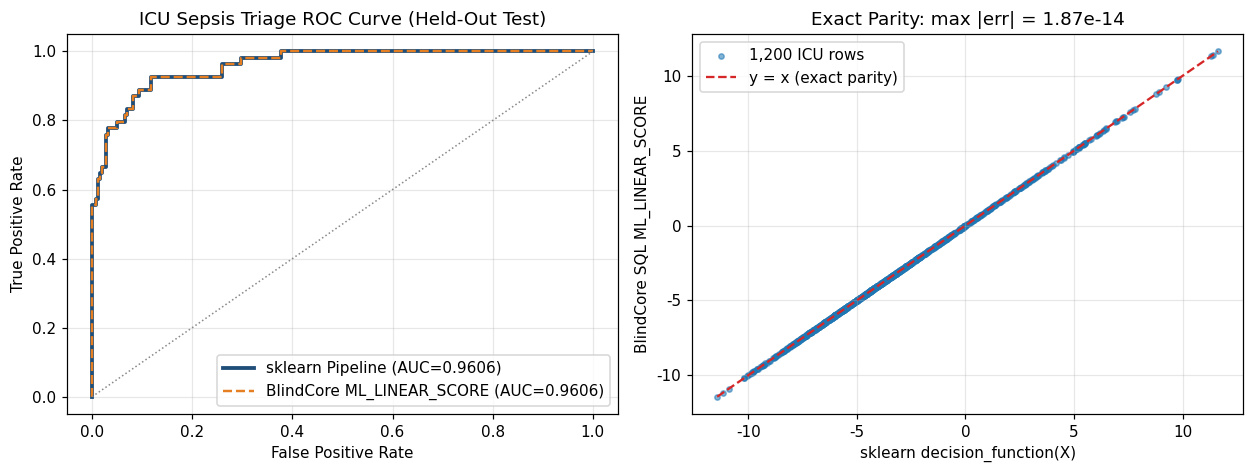

Live BlindCore Query Latency Scorecard (AlmaLinux 10.3 ARM64, TLS 1.3)
+----------------------------------+-------+-------------+--------------+
| Operation                        |  Rows | TLS RTT(ms) | Engine (us)  |
+----------------------------------+-------+-------------+--------------+
| Heartbeat SELECT 1               |     1 |      392.08 |           92 |
| DDL CREATE TABLE                 |     0 |      170.41 |          111 |
| Check existing rows              |     1 |      151.59 |          175 |
| INSERT batch 1-300               |     0 |      214.22 |         6030 |
| INSERT batch 301-600             |     0 |      207.76 |         5455 |
| INSERT batch 601-900             |     0 |      244.18 |         5739 |
| INSERT batch 901-1200            |     0 |      324.37 |         5726 |
| Verify row count                 |     1 |      168.34 |         1671 |
| Global vitals AVG/COUNT          |     1 |      152.70 |          469 |
| WHERE sepsis_flag = 1            |     

In [6]:
fpr_sk, tpr_sk, _ = roc_curve(y_test, sk_logits_all[idx_test])
fpr_sql, tpr_sql, _ = roc_curve(y_test, sql_logits_all[idx_test])

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), dpi=110)

axes[0].plot(fpr_sk, tpr_sk, lw=2.5, color="#1f4e79", label=f"sklearn Pipeline (AUC={roc_auc:.4f})")
axes[0].plot(fpr_sql, tpr_sql, lw=1.6, ls="--", color="#e67e22", label=f"BlindCore ML_LINEAR_SCORE (AUC={sql_roc_test:.4f})")
axes[0].plot([0, 1], [0, 1], lw=1.0, ls=":", color="#888888")
axes[0].set_title("ICU Sepsis Triage ROC Curve (Held-Out Test)")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right", frameon=True)
axes[0].grid(alpha=0.3)

axes[1].scatter(sk_logits_all, sql_logits_all, s=12, alpha=0.55, color="#1f77b4", label="1,200 ICU rows")
lo = min(float(sk_logits_all.min()), float(sql_logits_all.min()))
hi = max(float(sk_logits_all.max()), float(sql_logits_all.max()))
axes[1].plot([lo, hi], [lo, hi], color="#d62728", lw=1.5, ls="--", label="y = x (exact parity)")
axes[1].set_title(f"Exact Parity: max |err| = {abs_diff_all.max():.2e}")
axes[1].set_xlabel("sklearn decision_function(X)")
axes[1].set_ylabel("BlindCore SQL ML_LINEAR_SCORE")
axes[1].legend(loc="upper left", frameon=True)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

summary_rows = [r for r in latency_log if not r[0].startswith("ML_LINEAR_SCORE alert probe #")]
summary_rows.append((
    "ML_LINEAR_SCORE alert (10x p50)",
    1,
    pct(probe_rtts, 50),
    int(round(pct(probe_eng_us, 50))),
))
summary_rows.append((
    "ML_LINEAR_SCORE alert (10x p95)",
    1,
    pct(probe_rtts, 95),
    int(round(pct(probe_eng_us, 95))),
))

print("Live BlindCore Query Latency Scorecard (AlmaLinux 10.3 ARM64, TLS 1.3)")
print("+----------------------------------+-------+-------------+--------------+")
print("| Operation                        |  Rows | TLS RTT(ms) | Engine (us)  |")
print("+----------------------------------+-------+-------------+--------------+")
for label, rcnt, rtt, eus in summary_rows:
    print(f"| {label:<32s} | {rcnt:5d} | {rtt:11.2f} | {eus:12d} |")
print("+----------------------------------+-------+-------------+--------------+")